# Part B · Lie Factor, in code (15 marks)

`Lie Factor = (effect shown in the graphic) / (effect in the data)`, where `effect = (final − initial) / initial`.
Honest is 1.0; Tufte accepts 0.95 – 1.05.

**Run order:** just *Run All*. Needs `vizlib.py` and `data/case07_lie_factor.csv` (see README).

In [1]:
# --- Setup: finds vizlib.py and data/ wherever this notebook is saved ---------------
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

def find_assignments_dir():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        for cand in (p, p / "assignments", p / "week3" / "assignments"):
            if (cand / "vizlib.py").exists() and (cand / "data").is_dir():
                return cand
    raise FileNotFoundError(
        "Could not find vizlib.py + data/. Save this notebook inside "
        "week3/assignments/ (next to vizlib.py) - see README.md.")

ROOT = Path(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
OUT = ROOT / "outputs"            # every PNG this notebook writes lands here
OUT.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from vizlib import (PALETTE, MARKERS, style_defaults, save_fig, lie_factor,
                    lie_verdict, simulate_cvd, worst_pair, verdict, delta_e)

style_defaults()                  # house look, set once (slide 26)
BLUE, ORANGE, GREEN = PALETTE["series"]
print("ROOT:", ROOT)

ROOT: C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3


## Q1 · The audit table (5 marks)
One call to `vizlib.lie_factor()` per graphic, using the `ink_dimension` the file gives us.

In [2]:
lf_df = pd.read_csv(DATA / "case07_lie_factor.csv")

rows = []
for r in lf_df.itertuples():
    lf, data_eff, graphic_eff = lie_factor(r.value_start, r.value_end,
                                           r.ink_start, r.ink_end,
                                           ink_dimension=int(r.ink_dimension))
    rows.append({"chart": r.chart_id, "subject": r.subject,
                 "ink_dim": int(r.ink_dimension),
                 "data effect": data_eff, "graphic effect": graphic_eff,
                 "Lie Factor": lf, "verdict": lie_verdict(lf)})
audit = pd.DataFrame(rows).set_index("chart")

display(audit.style.format({"data effect": "{:+.1%}", "graphic effect": "{:+.1%}",
                            "Lie Factor": "{:.2f}"}))

,subject,ink_dim,data effect,graphic effect,Lie Factor,verdict
chart,,,,,,
A,Corporate tax rate,1,+6.7%,+500.0%,75.00,exaggerates 75.00x
B,Federal health budget (Rs bn),2,+50.0%,+125.0%,2.50,exaggerates 2.50x
C,Export earnings ($ bn),1,+20.0%,+20.0%,1.00,honest
D,Air-pollution index,1,+50.0%,+12.5%,0.25,understates (0.25)
E,City population (millions),2,+300.0%,+1500.0%,5.00,exaggerates 5.00x


## Q2 · Exactly one is honest (3 marks)

**C (export earnings) is the honest one: LF = 1.00.** Bars start at zero and the ink grows 5.0 → 6.0 cm (+20%) for a data rise of 25 → 30 (+20%).
The other four, in terms of *what the ink is encoding*:

| Chart | What the ink actually encodes | Lie Factor |
|---|---|---|
| **A** corporate tax | Bars start at 29.6%, so the ink length encodes *value − 29.6*, not the value. A 2-point rise (+6.7%) is drawn as a +500% rise. | **75.0** |
| **B** health budget | A coin icon scaled 1.5× in height *and* width. Ink is area, which grows as 1.5² = 2.25×, so +50% data reads as +125%. | **2.50** |
| **D** pollution index | Ink grows only 8 → 9 cm (+12.5%) for a +50% rise in the data. The change is compressed. | **0.25** |
| **E** city population | Bubble *radius* set proportional to the value. Area goes as r², so a 4× value becomes a 16× bubble (+1,500% vs +300%). | **5.00** |

## Q3 · Which need `ink_dimension=2`, and what breaks at 1? (3 marks)

In [3]:
two_d = lf_df.loc[lf_df.ink_dimension == 2, "chart_id"].tolist()
print("Charts that need ink_dimension=2:", two_d, "\n")

# what happens if we leave it at 1 for those two
for r in lf_df[lf_df.ink_dimension == 2].itertuples():
    wrong, *_ = lie_factor(r.value_start, r.value_end, r.ink_start, r.ink_end, ink_dimension=1)
    right, *_ = lie_factor(r.value_start, r.value_end, r.ink_start, r.ink_end, ink_dimension=2)
    print(f"Chart {r.chart_id}: LF with ink_dimension=1 -> {wrong:.2f} ({lie_verdict(wrong)})"
          f"   |   with ink_dimension=2 -> {right:.2f} ({lie_verdict(right)})")

Charts that need ink_dimension=2: ['B', 'E'] 

Chart B: LF with ink_dimension=1 -> 1.00 (honest)   |   with ink_dimension=2 -> 2.50 (exaggerates 2.50x)
Chart E: LF with ink_dimension=1 -> 1.00 (honest)   |   with ink_dimension=2 -> 5.00 (exaggerates 5.00x)


**Charts B and E.** Both encode the value by an *area* (an icon scaled in two dimensions, a bubble sized by radius), so the reader's eye sees ink ∝ scale². If you leave `ink_dimension=1` you measure only the linear scale factor, which for both charts equals the data effect exactly. Both come out at LF = 1.00 and the audit certifies two badly exaggerated graphics as **honest**.

## Q4 · The chart with Lie Factor below 1 (2 marks)

In [4]:
d = audit.loc["D"]
print(f"Chart D: data effect {d['data effect']:+.1%}, graphic effect {d['graphic effect']:+.1%}, LF {d['Lie Factor']:.2f}")

Chart D: data effect +50.0%, graphic effect +12.5%, LF 0.25


**Chart D (LF = 0.25).** An understated chart is still a distortion because the formula is symmetric: the graphic no longer carries the size of the change. Readers come away thinking the pollution index barely moved when it rose by half (100 → 150). Understatement is the **less popular** lie, but it is just as much a lie.

**Who benefits:** whoever would prefer the rise go unnoticed, such as a regulator who wants to show the air is "stable" or the emitters responsible for the increase. Exaggeration is used to alarm; understatement is used to reassure.

## Q5 · Chart F, the dual-axis chart from Part A case 7 (2 marks)

In [5]:
ser = pd.read_csv(DATA / "case07_dual_axis_series.csv")

# What the Part A recipe drew: revenue on a 50-80 axis, cost on a 40-56 axis.
def ink_from_axis_floor(v, lo, hi):          # height above the axis floor, as a 0..1 fraction
    return (v - lo) / (hi - lo)

rev_lf = lie_factor(ser.revenue_pkr_m.iloc[0], ser.revenue_pkr_m.iloc[-1],
                    ink_from_axis_floor(ser.revenue_pkr_m.iloc[0], 50, 80),
                    ink_from_axis_floor(ser.revenue_pkr_m.iloc[-1], 50, 80))
cost_lf = lie_factor(ser.cost_pkr_m.iloc[0], ser.cost_pkr_m.iloc[-1],
                     ink_from_axis_floor(ser.cost_pkr_m.iloc[0], 40, 56),
                     ink_from_axis_floor(ser.cost_pkr_m.iloc[-1], 40, 56))
print(f"Revenue line 'LF' if you measure ink from the axis floor: {rev_lf[0]:.1f}")
print(f"Cost line    'LF' if you measure ink from the axis floor: {cost_lf[0]:.1f}")
print("...and those two numbers change to anything you like if the axis limits change. They mean nothing.\n")

gap = ser.assign(gap_pkr_m=ser.revenue_pkr_m - ser.cost_pkr_m,
                 margin=(ser.revenue_pkr_m - ser.cost_pkr_m) / ser.revenue_pkr_m)
display(gap.style.format({"margin": "{:.1%}"}))

Revenue line 'LF' if you measure ink from the axis floor: 26.0
Cost line    'LF' if you measure ink from the axis floor: 11.0
...and those two numbers change to anything you like if the axis limits change. They mean nothing.



,month,revenue_pkr_m,cost_pkr_m,gap_pkr_m,margin
0,Jan,52,44,8,15.4%
1,Feb,58,46,12,20.7%
2,Mar,61,47,14,23.0%
3,Apr,66,49,17,25.8%
4,May,71,51,20,28.2%
5,Jun,78,53,25,32.1%


**The Lie Factor cannot be computed for Chart F.** The formula assumes one quantity drawn on one scale, so that a ratio of ink means a ratio of values. A dual-axis chart breaks that: each line has its own arbitrary mapping `ink = a·v + b`, chosen by the designer. The "ink effect" can be dialled to any value by changing the axis limits, so a Lie Factor would measure the designer's axis choice, not the data. (The two numbers above are what you get *if* you measure from each axis floor. They are artefacts.)

**What the data actually shows:** revenue is above cost in **every month**. The gap grows from PKR 8 m (Jan) to PKR 25 m (Jun), and the margin from 15.4% to 32.1%. ShaheenGo was never at a loss. The "loss until May" story exists only because the two axes were set independently, so the lines cross on screen but never in the numbers.

## Extra · All five on one picture
A dot plot on a log axis, with stems anchored at the honest value 1.0. (Bars on a log axis would have an arbitrary length, which is the very sin this part audits.)

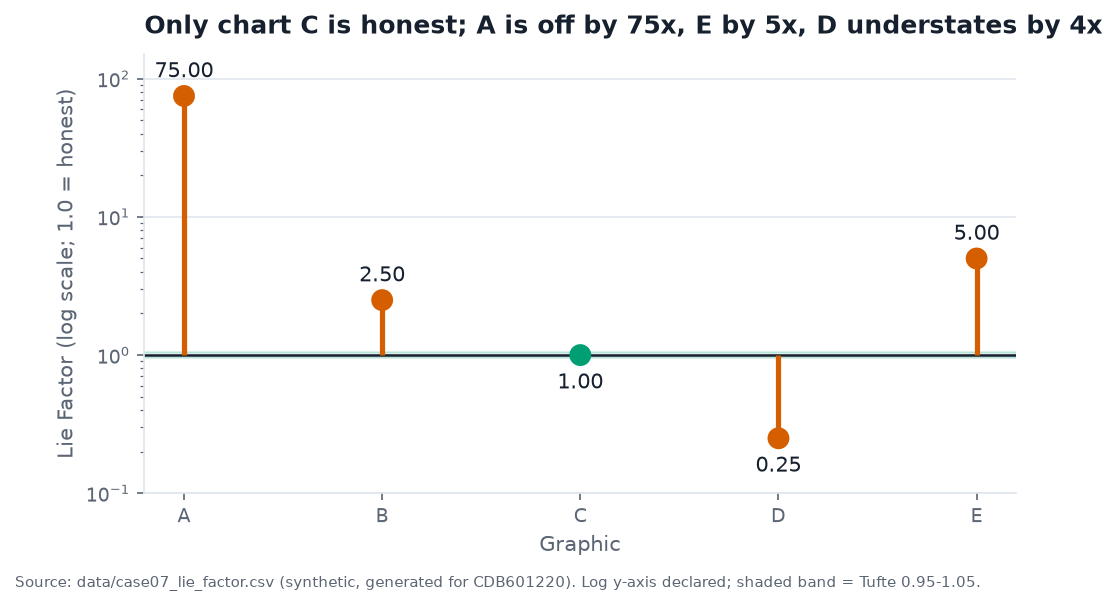

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
lfs = audit["Lie Factor"]
is_ok = (lfs >= 0.95) & (lfs <= 1.05)
cols = [GREEN if ok else PALETTE["highlight"] for ok in is_ok]
ax.axhspan(0.95, 1.05, color=GREEN, alpha=0.15, zorder=0)     # Tufte's 0.95-1.05 band
ax.axhline(1.0, color=PALETTE["ink"], lw=1.2, zorder=1)
ax.vlines(range(len(lfs)), 1.0, lfs, color=cols, lw=2.5, zorder=2)
ax.scatter(range(len(lfs)), lfs, color=cols, s=90, zorder=3,
           marker="o")
for i, v in enumerate(lfs):
    ax.annotate(f"{v:.2f}", (i, v), textcoords="offset points",
                xytext=(0, 9 if v >= 1 else -16), ha="center")
ax.set_yscale("log")
ax.set_ylim(0.1, 150)
ax.set_xticks(range(len(lfs)), lfs.index)
ax.set_ylabel("Lie Factor (log scale; 1.0 = honest)")
ax.set_xlabel("Graphic")
ax.set_title("Only chart C is honest; A is off by 75x, E by 5x, D understates by 4x")
ax.grid(axis="x", visible=False)
save_fig(fig, OUT / "partB_lie_factor.png",
         "Source: data/case07_lie_factor.csv (synthetic, generated for CDB601220). Log y-axis declared; shaded band = Tufte 0.95-1.05.")
plt.show()